In [ ]:
from datetime import datetime
from IPython.display import display, Markdown
from zoneinfo import ZoneInfo

current_date = datetime.now(ZoneInfo('America/Mexico_City')).strftime("%Y-%m-%d %H:%M:%S")
formatted_text = f"""
# <font color='orange'> Fourier Analysis
<font color='green'> Made by: J. Daniel Arzate | Date: 2020 - Enero 19 </font>

<font color='red'> Las view: {current_date}</font>
"""
display(Markdown(formatted_text))


# <font color='orange'> Fourier Analysis
<font color='green'> Made by: J. Daniel Arzate | Date: 2020 - Enero 19 </font>

<font color='red'> Las view: 2026-10-21 09:37:43</font>


# Teoría

## Análisis en el dominio de la frecuencia: la transformada de Fourier y el PSD

El análisis en el dominio de la frecuencia, también conocido como *análisis espectral*, estudia el contenido de frecuencia de los datos, es decir, estudia la importancia relativa de la variabilidad de la señal a diferentes escalas de tiempo. Esto se hace aplicando primero la transformación de Fourier a los datos, pasando la serie del espacio del tiempo al espacio de la frecuencia.

La herramienta principal es el **PSD** (o Power Spectral Density), también conocido como *espectro de potencia* (o *power spectrum*). Se define como:

$$ PSD \equiv \left| \mathscr{F}[ h(t) ] \right|^2 $$

donde $\mathscr{F}[h(t)]$ es la *transformada de Fourier* de la serie de tiempo $h(t)$:

$$ \mathscr{F}[h(t)] \equiv H(f) \equiv \int_{-\infty}^{\infty} h(t) e^{-i  2\pi ft} dt$$

En principio, la transformada de Fourier ([FT](https://es.wikipedia.org/wiki/Densidad_espectral)) nos da principalmente información sobre dos cosas:

* Las **periodicidades**, visibles en forma de picos delgados a frecuencias determinadas
* Las **auto-correlaciones en las fluctuaciones** de la serie

* Existe una relación directa entre la función de Autocorrelación y el Espectro de Potencias (SPD) a través del teorema [**Wiener–Khinchin theorem**](https://mathworld.wolfram.com/Wiener-KhinchinTheorem.html)

$$ S_{xx}(\omega) = \mathscr{F}(r_{xx}(\tau)) =  \int_{-\infty }^{\infty } r_{xx}(\tau) e^{-i 2 \pi f \tau} d\tau$$

* Ejemplo Aplicado (Python): http://pdebuyl.be/blog/2017/wiener-khinchin.html

# Aplicación

## Señal Sinusidales

In [ ]:
#@title Libraries
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
#@title Main-Sin_Signal

# Parameters
DURATION = 1.0    # seconds
SAMPLING_RATE = 32   # Hz -> Originalmente 2**5
FREQUENCY = 2   # Hz

# Time vectors
t_continuous = np.linspace(0, DURATION, int(1000 * DURATION) )  # only for plotting
t_discrete = np.arange(0, DURATION, 1 / SAMPLING_RATE)        # [0, DURATION), 32 samples: np.arange(start, stop, step) 'stop' not-included

# Signals
AMPLITUDE = 4.0      # signal amplitude (units)
continuous_signal = AMPLITUDE * np.sin(2 * np.pi * FREQUENCY * t_continuous)
discrete_signal = AMPLITUDE * np.sin(2 * np.pi * FREQUENCY * t_discrete)


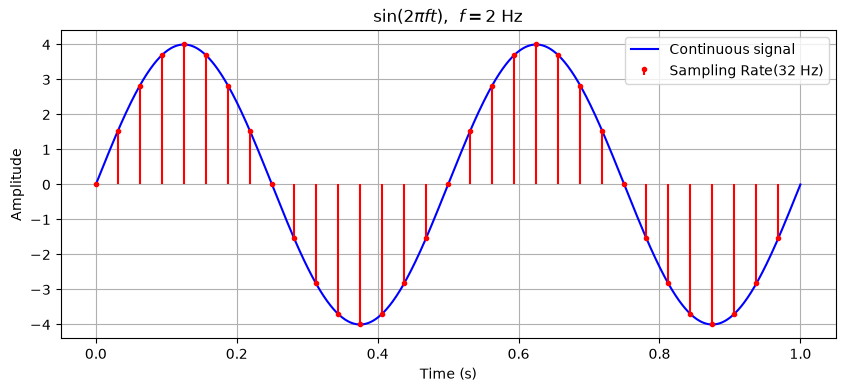

In [ ]:
#@title Plot

plt.figure(figsize=(10, 4))
plt.plot(t_continuous, continuous_signal, label='Continuous signal', color='b')
#plt.plot(t_discrete, discrete_signal, 'r--', alpha=0.5)
plt.stem(t_discrete, discrete_signal,label=f'Sampling Rate({SAMPLING_RATE} Hz)', basefmt=" ", linefmt='r', markerfmt='r.')


plt.title(rf'$\sin(2\pi f t)$,  $f = {FREQUENCY}$ Hz')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid()
plt.legend()
plt.show()

## Dominio del Tiempo
   

### **Efecto de la frecuencia de la señal ($f$):**
   * Ajusta `SAMPLING_RATE = 32 Hz`. ¿Qué ocurre con la gráfica discreta (puntos rojos) conforme incrementas `FREQUENCY` a $4\text{ Hz}$, $8\text{ Hz}$, $16\text{ Hz}$, $30\text{ Hz}$ y $33\text{ Hz}$?
   * ¿Por qué la señal muestreada de $30\text{ Hz}$ aparenta oscilar a una frecuencia mucho más baja ($2\text{ Hz}$)?. <br>
   $R:$   
   - El aliasing ocurre porque el sistema de muestreo es demasiado lento para registrar los ciclos de la onda original, obligando al hardware a unir puntos de captura desfasados que construyen la ilusión de una señal de baja frecuencia
   - Cuando la tasa de muestreo es incapaz de registrar un mínimo de dos puntos por ciclo, la señal original se vuelve irreconstruible y el sistema la interpreta erróneamente como una onda fantasma más lenta, denominada alias


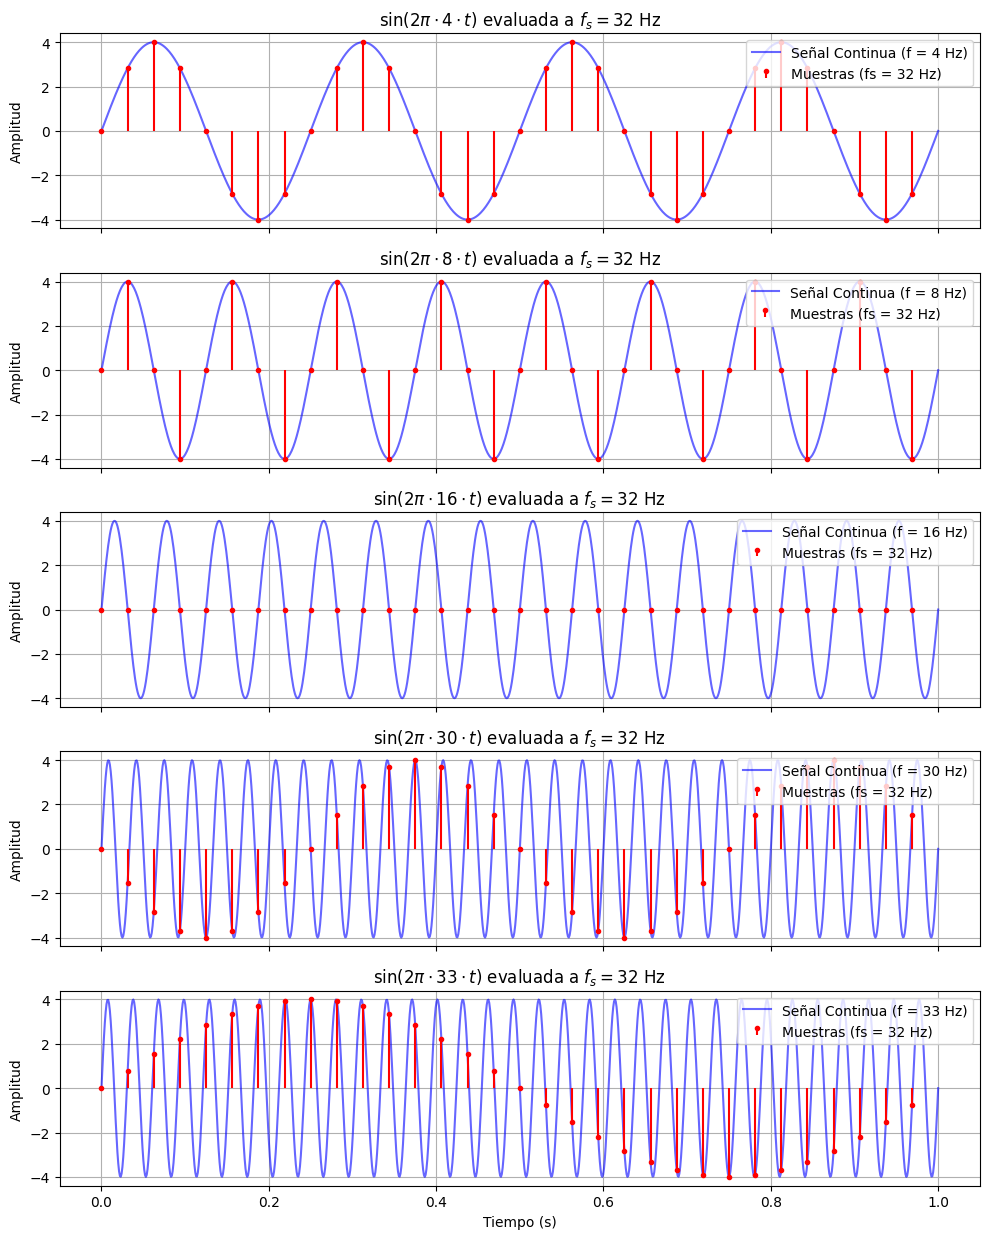

In [ ]:
SAMPLING_RATE = 32 # Hz (Tasa estática del "hardware")
AMPLITUDE = 4.0    # Amplitud de la señal

# Vector de frecuencias de la señal a evaluar (Hz)
frecuencias_senal = [4, 8, 16, 30, 33]

# Vectores de tiempo
# t_continuous: alta resolución para visualizar el comportamiento continuo real
t_continuous = np.linspace(0, DURATION, int(1000 * DURATION))
# t_discrete: instantes de muestreo gobernados por SAMPLING_RATE
t_discrete = np.arange(0, DURATION, 1 / SAMPLING_RATE)

# Instanciamos una matriz de figuras (5 filas, 1 columna) para aislar cada análisis
fig, axes = plt.subplots(len(frecuencias_senal), 1, figsize=(10, 2.5 * len(frecuencias_senal)), sharex=True)

# Bucle analítico
for i, f in enumerate(frecuencias_senal):
    # 1. Modelado matemático de las señales en la iteración actual
    continuous_signal = AMPLITUDE * np.sin(2 * np.pi * f * t_continuous)
    discrete_signal = AMPLITUDE * np.sin(2 * np.pi * f * t_discrete)

    # 2. Trazado de las proyecciones en el sub-gráfico correspondiente
    axes[i].plot(t_continuous, continuous_signal, label=f'Señal Continua (f = {f} Hz)', color='b', alpha=0.6)
    axes[i].stem(t_discrete, discrete_signal, label=f'Muestras (fs = {SAMPLING_RATE} Hz)', basefmt=" ", linefmt='r', markerfmt='r.')

    # 3. Formateo y metadatos rigurosos de cada eje
    axes[i].set_title(rf'$\sin(2\pi \cdot {f} \cdot t)$ evaluada a $f_s = {SAMPLING_RATE}$ Hz')
    axes[i].set_ylabel('Amplitud')
    axes[i].grid(True)
    axes[i].legend(loc='upper right')

axes[-1].set_xlabel('Tiempo (s)')
plt.tight_layout()
plt.show()

### **Límite de Nyquist y Colapso de Fase:**
   * Si mantienes `SAMPLING_RATE = 32 Hz` y fijas `FREQUENCY = 16 Hz` ($f_{sin} = f_{srate} / 2$), ¿qué forma adquieren los puntos muestreados?
   $R:$ Los puntos muestreados colapsan en 0, adquiriendo la forma de una constante nula. Esto ocurre porque el sistema opera exactamente en el Límite de Nyquist ($f_s = 2f$), lo que provoca que las capturas coincidan exclusivamente con los cruces por cero de la onda periódica, perdiendo así toda la información de amplitud
   
   * ¿Qué pasaría si introducimos un desfase $\phi = \pi/2$ (usando $\cos$ en lugar de $\sin$)? ¿Detectaríamos la onda o una constante?
   $R:$ Al introducir el desfase de $\pi/2$, las capturas coinciden perfectamente con los máximos (+4) y mínimos (-4) de la función. Esto permite registrar la envolvente espacial de la señal original y evitar la constante nula.


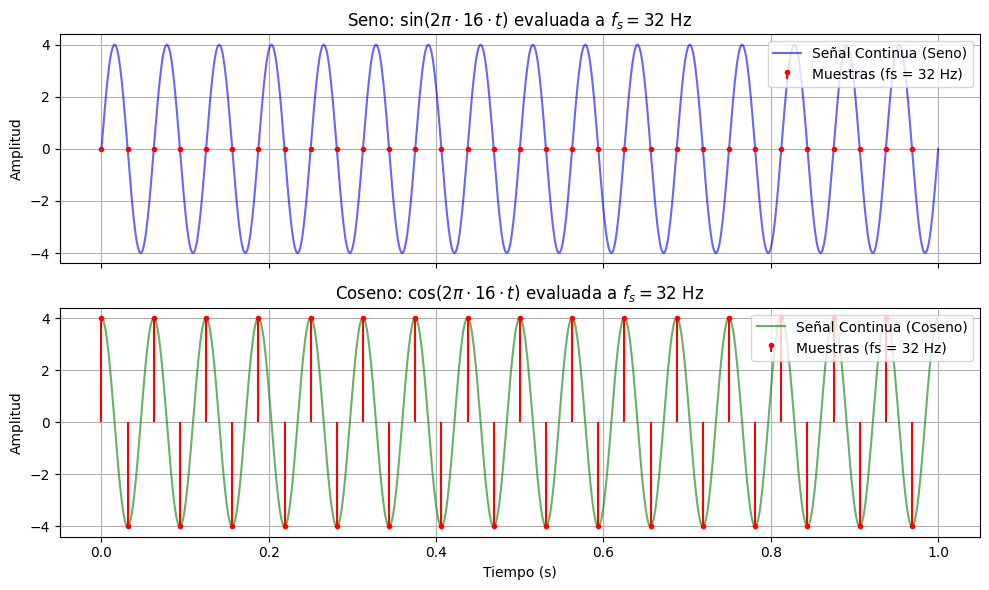

In [ ]:
# Parámetros Base
DURATION = 1.0     # Segundos
SAMPLING_RATE = 32 # Hz
FREQUENCY = 16     # Hz (Límite exacto de Nyquist: fs / 2)
AMPLITUDE = 4.0    # Amplitud de la señal

# Vectores de tiempo
t_continuous = np.linspace(0, DURATION, int(1000 * DURATION))
t_discrete = np.arange(0, DURATION, 1 / SAMPLING_RATE)

# 1. Señal sin desfase (Seno)
continuous_sin = AMPLITUDE * np.sin(2 * np.pi * FREQUENCY * t_continuous)
discrete_sin = AMPLITUDE * np.sin(2 * np.pi * FREQUENCY * t_discrete)

# 2. Señal con desfase de pi/2 (Coseno)
continuous_cos = AMPLITUDE * np.cos(2 * np.pi * FREQUENCY * t_continuous)
discrete_cos = AMPLITUDE * np.cos(2 * np.pi * FREQUENCY * t_discrete)

# Configuración de la figura
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Gráfico 1: Seno
axes[0].plot(t_continuous, continuous_sin, label='Señal Continua (Seno)', color='b', alpha=0.6)
axes[0].stem(t_discrete, discrete_sin, label=f'Muestras (fs = {SAMPLING_RATE} Hz)', basefmt=" ", linefmt='r', markerfmt='r.')
axes[0].set_title(rf'Seno: $\sin(2\pi \cdot {FREQUENCY} \cdot t)$ evaluada a $f_s = {SAMPLING_RATE}$ Hz')
axes[0].set_ylabel('Amplitud')
axes[0].grid(True)
axes[0].legend(loc='upper right')

# Gráfico 2: Coseno
axes[1].plot(t_continuous, continuous_cos, label='Señal Continua (Coseno)', color='g', alpha=0.6)
axes[1].stem(t_discrete, discrete_cos, label=f'Muestras (fs = {SAMPLING_RATE} Hz)', basefmt=" ", linefmt='r', markerfmt='r.')
axes[1].set_title(rf'Coseno: $\cos(2\pi \cdot {FREQUENCY} \cdot t)$ evaluada a $f_s = {SAMPLING_RATE}$ Hz')
axes[1].set_ylabel('Amplitud')
axes[1].set_xlabel('Tiempo (s)')
axes[1].grid(True)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

### **Reducción de la Tasa de Muestreo ($f_{srate}$):**
   * Deja `FREQUENCY = 4 Hz` y reduce `SAMPLING_RATE` paulatinamente ($64 \to 32 \to 16 \to 8 \to 4$). ¿En qué punto la reconstrucción discreta deja de representar fielmente a la onda continua original?

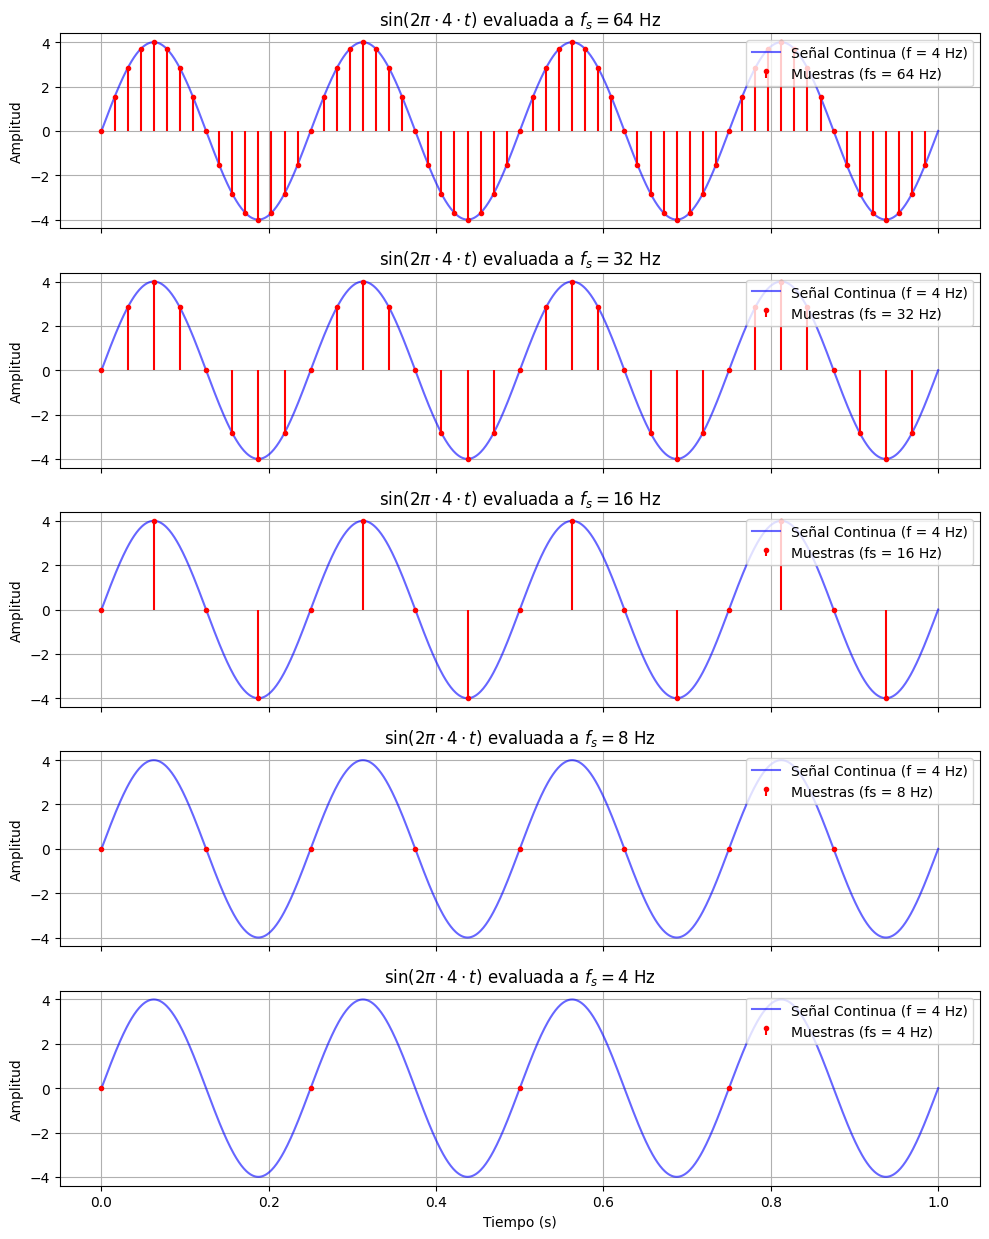

In [ ]:
# Parámetros Base
DURATION = 1.0     # Segundos
FREQUENCY = 4      # Hz (Frecuencia de la señal estática)
AMPLITUDE = 4.0    # Amplitud de la señal

# Vector de tasas de muestreo a evaluar (Hz)
tasas_muestreo = [64, 32, 16, 8, 4]

# Vector de tiempo continuo (Alta resolución para la onda azul original)
t_continuous = np.linspace(0, DURATION, int(1000 * DURATION))
# Modelado de la señal continua estática
continuous_signal = AMPLITUDE * np.sin(2 * np.pi * FREQUENCY * t_continuous)

# Instanciamos la matriz de figuras
fig, axes = plt.subplots(len(tasas_muestreo), 1, figsize=(10, 2.5 * len(tasas_muestreo)), sharex=True)

# Bucle analítico para variar fs
for i, fs in enumerate(tasas_muestreo):
    # 1. Recálculo del vector de tiempo discreto dependiente de fs
    t_discrete = np.arange(0, DURATION, 1 / fs)

    # 2. Modelado de la señal digitalizada
    discrete_signal = AMPLITUDE * np.sin(2 * np.pi * FREQUENCY * t_discrete)

    # 3. Trazado de las gráficas
    axes[i].plot(t_continuous, continuous_signal, label=f'Señal Continua (f = {FREQUENCY} Hz)', color='b', alpha=0.6)
    axes[i].stem(t_discrete, discrete_signal, label=f'Muestras (fs = {fs} Hz)', basefmt=" ", linefmt='r', markerfmt='r.')

    # 4. Formateo de los ejes
    axes[i].set_title(rf'$\sin(2\pi \cdot {FREQUENCY} \cdot t)$ evaluada a $f_s = {fs}$ Hz')
    axes[i].set_ylabel('Amplitud')
    axes[i].grid(True)
    axes[i].legend(loc='upper right')

axes[-1].set_xlabel('Tiempo (s)')
plt.tight_layout()
plt.show()

### **Límite Continuo vs. Discreto:**
   * En la simulación usamos `np.linspace(..., 1000)` para simular el tiempo "continuo". En una computadora digital, ¿existe la señal verdaderamente continua o solo tenemos muestreos muy densos?

En una computadora digital, la señal verdaderamente continua no existe. Lo que denominamos 'tiempo continuo' en la simulación es, arquitectónicamente, un vector discreto con una resolución temporal densa ($1000\text{ Hz}$), acotado por el formato de representación de coma flotante y la memoria física del sistema. Las gráficas aparentan continuidad únicamente mediante la interpolación lineal entre estos puntos subyacentes.

## Suma de Señales

Vamos a construir una serie de tiempo artificial sumando las siguientes componentes:

* un seno con frecuencia 2 Hz
* un seno con frecuencia 3 Hz
* Ambas con $A_i(amplitud) = 2$

A continuación construimos esta señal:

In [ ]:
#@title Main-sum_sines

####### Parameters
SAMPLING_RATE = 2**8                    # 256 samples per second
SAMPLING_PERIOD = 1 / SAMPLING_RATE     # seconds between samples
DURATION = 5.0                          # seconds to record

N_SAMPLES = int(SAMPLING_RATE * DURATION)          # samples in the window
time = np.arange(0, DURATION, SAMPLING_PERIOD)     # discrete time vector [0, DURATION)

####### Amplitudes & frequencies
A1 = 2.0
F1 = 2.0
A2 = 2.0
F2 = 3.0

signal_1 = A1 * np.sin(2 * np.pi * F1 * time)
signal_2 = A2 * np.sin(2 * np.pi * F2 * time)
signal = signal_1 + signal_2


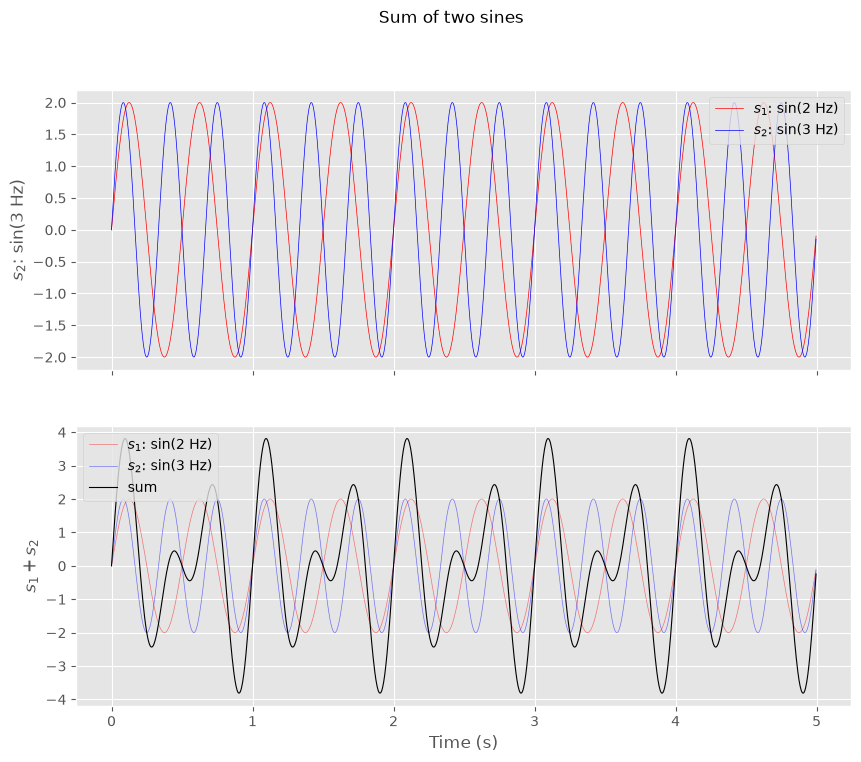

In [ ]:
####### Plot
with plt.style.context('ggplot'):
  fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

  axes[0].plot(time, signal_1, color='r', linewidth=0.5,label=f'$s_1$: sin({F1:g} Hz)')
  axes[0].set_ylabel(f'$s_1$: sin({F1:g} Hz)')

  axes[0].plot(time, signal_2, color='b', linewidth=0.5,label=f'$s_2$: sin({F2:g} Hz)')
  axes[0].set_ylabel(f'$s_2$: sin({F2:g} Hz)')
  axes[0].legend(loc='upper right')


  axes[1].plot(time, signal_1, color='r', linewidth=0.5, alpha=0.5, label=f'$s_1$: sin({F1:g} Hz)')
  axes[1].plot(time, signal_2, color='b', linewidth=0.5, alpha=0.5, label=f'$s_2$: sin({F2:g} Hz)')
  axes[1].plot(time, signal, color='k', linewidth=0.8, label= 'sum')
  axes[1].set_ylabel('$s_1 + s_2$')
  axes[1].set_xlabel('Time (s)')
  axes[1].legend(loc = 'upper left')

  fig.suptitle('Sum of two sines')

  plt.show()

# FFT (Espectro de Potencia)

In [ ]:
#@title Libraries
from scipy.fft import fft, fftfreq

signal: (1280,), spectrum: (1280,), one-sided: (640,)


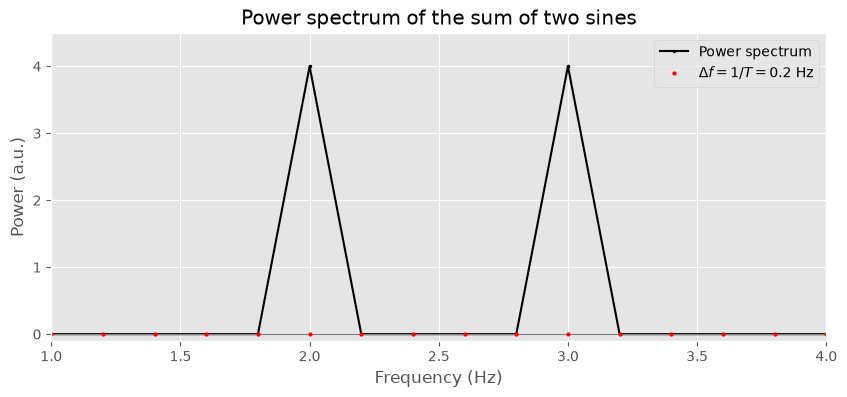

In [ ]:
#@title Main Program
spectrum = fft(signal)                        # complex coefficients
amplitude = 2 * np.abs(spectrum[:N_SAMPLES // 2]) / N_SAMPLES   # one-sided amplitude
power_spectrum = amplitude**2                 # power ~ A²

frequencies = fftfreq(N_SAMPLES, SAMPLING_PERIOD)[:N_SAMPLES // 2]

print(f"signal: {signal.shape}, spectrum: {spectrum.shape}, "f"one-sided: {amplitude.shape}")        # length = DURATION * SAMPLING_RATE = 1280

######### Plot
with plt.style.context('ggplot'):
    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(frequencies, power_spectrum, 'k-', marker='.', markersize=3, label='Power spectrum')
    ax.axhline(0, color='gray', linewidth=0.8)          # reference line at y=0

    # markers showing the frequency resolution (distance between bins = 1/DURATION)
    bin_spacing = np.zeros_like(power_spectrum)
    ax.plot(frequencies, bin_spacing, 'r.', markersize=4, label=rf'$\Delta f = 1/T = {1/DURATION:g}$ Hz')

    ax.set_title('Power spectrum of the sum of two sines')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power (a.u.)')
    ax.set_xlim(1, 4)
    ax.set_ylim(-0.1, 4.5)
    ax.legend()
    plt.show()

## ⭕ Dominio de la Frecuencia (PSD)


Pista:

El bin $k$ de la FFT corresponde a la frecuencia:

$$f_k = \frac{k}{N \cdot \Delta t} = k \cdot \Delta f, \quad \Delta f = \frac{1}{T} = \frac{f_s}{N}$$

y los bins con $k > N/2$ son frecuencias negativas "plegadas" (equivale a $k - N$).


### Genera la misma gráfica pero con f2=2.9. ¿Qué sucede con la amplitud y la potencia?

- **Spectral Leakage**: Como la $f_2$=2.9 esto no es un contenedor discreto de la *FFT* así que distribuye los puntos entre 2.8 y 3.0 con  $\Delta f = 0.2\text{ Hz}$ (la energía de esa frecuencia no puede depositarse en un solo punto)
- **Potencia pico**:  La potencia máxima proyectada en el gráfico para la componente de $2.9\text{ Hz}$ disminuye debido a que la energía se "fuga" hacia los bins adyacentes ($2.8\text{ Hz}$ y $3.0\text{ Hz}$)

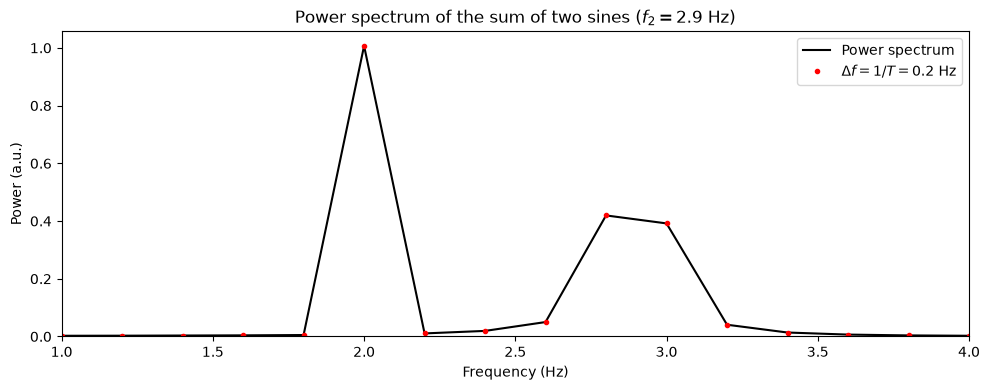

In [ ]:
# 1. Configuración de parámetros temporales y de muestreo
fs = 100.0                  # Tasa de muestreo (Hz)
T = 5.0                     # Duración del registro (s) -> Δf = 1/T = 0.2 Hz
N = int(fs * T)             # Número total de muestras (N = 500)
t = np.linspace(0, T, N, endpoint=False)

# 2. Frecuencias de las señales sinusoidales (f2 cambiada a 2.9 Hz)
f1 = 2.0
f2 = 2.9                    # No es múltiplo entero de Δf (2.9 / 0.2 = 14.5)

# 3. Generación de la señal sumada
x = np.sin(2 * np.pi * f1 * t) + np.sin(2 * np.pi * f2 * t)

# 4. Cálculo de la FFT y vector de frecuencias
X = np.fft.fft(x)
freqs = np.fft.fftfreq(N, d=1/fs)

# 5. Filtrado de frecuencias positivas y cálculo del Espectro de Potencia (PSD)
pos_mask = (freqs >= 0) & (freqs <= fs / 2)
freqs_pos = freqs[pos_mask]

# Normalización estándar para que una sinusoide pura tenga potencia pico = 4.0
power_spectrum = (2.0 / N * np.abs(X[pos_mask])) ** 2

# 6. Visualización
delta_f = 1 / T

plt.figure(figsize=(10, 4))
plt.plot(freqs_pos, power_spectrum, 'k-', label='Power spectrum')
plt.plot(freqs_pos, power_spectrum, 'r.', label=rf'$\Delta f = 1/T = {delta_f:.1f}$ Hz')

plt.title('Power spectrum of the sum of two sines ($f_2 = 2.9$ Hz)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power (a.u.)')
plt.xlim(1.0, 4.0)
plt.ylim(bottom=0)
plt.legend()
plt.tight_layout()
plt.show()

### Si deseas distinguir los dos componentes frecuenciales cercanas ($2.0\text{ Hz}$ y $2.9\text{ Hz}$), ¿qué es más efectivo: aumentar la tasa de muestreo `SAMPLING_RATE` o aumentar la duración `DURATION` de la grabación? *(Pista: $\Delta f = 1 / T$)*

Lo mejor sería aumentar la `DURATION`
ya que:
1. **Efecto de aumentar $T$ (Duración):**

La resolución frecuencial es $\Delta f = \frac{1}{T}$. Al aumentar la duración del registro temporal $T$, la distancia entre los contenedores de la FFT ($\Delta f$) disminuye, haciendo que la rejilla del eje $X$ sea mucho más fina.

   - Si $T = 5\text{ s} \implies \Delta f = 0.2\text{ Hz}$ (los puntos están en $2.0, 2.2, 2.4, \dots, 2.8, 3.0\text{ Hz}$, perdiendo exactitud en $2.9\text{ Hz}$).
   - Si aumentas $T = 10\text{ s} \implies \Delta f = 0.1\text{ Hz}$ (ahora tienes puntos exactos en $2.0, 2.1, 2.2, \dots, 2.8, 2.9, 3.0\text{ Hz}$), separando limpiamente ambos picos.
2. **Por qué aumentar $f_s$ (Tasa de muestreo) NO sirve para esto:**

    Al aumentar $f_s$, incrementas el número total de muestras $N$, pero como $N = f_s \cdot T$, el cociente de la resolución permanece idéntico:
    $$\Delta f = \frac{f_s}{N} = \frac{f_s}{f_s \cdot T} = \frac{1}{T}$$

    Aumentar $f_s$ solo expande el eje $X$ hacia frecuencias más altas (mayor límite de Nyquist), pero no mejora la capacidad de distinguir frecuencias cercanas.

### Graficar $\phi_i(f_i)$ vs. $f_i$ Nota: $\phi_i = \arctan(\frac{I_i}{R_i})$ corresponde a las fases de Fourier

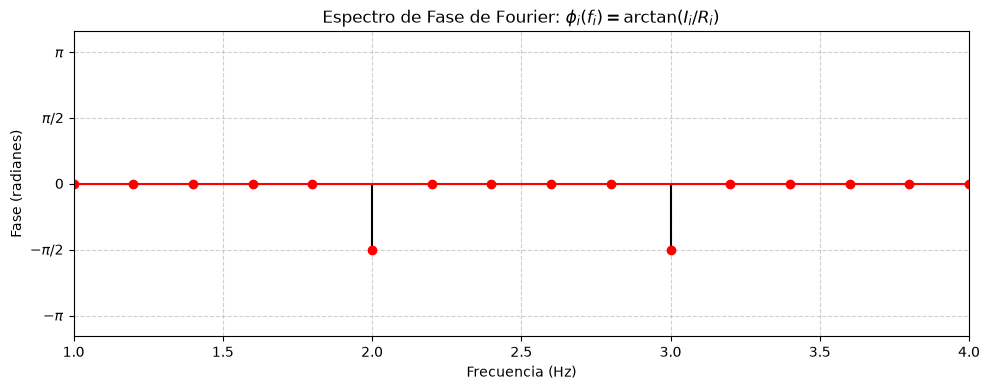

In [ ]:
# 1. Configuración de parámetros temporales y de muestreo
fs = 100.0                  # Tasa de muestreo (Hz)
T = 5.0                     # Duración del registro (s) -> Δf = 0.2 Hz
N = int(fs * T)             # Muestras totales (N = 500)
t = np.linspace(0, T, N, endpoint=False)

# 2. Generación de la señal (Suma de dos senos)
f1 = 2.0
f2 = 3.0
x = np.sin(2 * np.pi * f1 * t) + np.sin(2 * np.pi * f2 * t)

# 3. Transformada Rápida de Fourier (FFT)
X = np.fft.fft(x)
freqs = np.fft.fftfreq(N, d=1/fs)

# 4. Selección del espectro de frecuencias positivas (0 <= f <= fs/2)
pos_mask = (freqs >= 0) & (freqs <= fs / 2)
freqs_pos = freqs[pos_mask]
X_pos = X[pos_mask]

# 5. Extracción de partes Real (R_i) e Imaginaria (I_i)
R_i = np.real(X_pos)
I_i = np.imag(X_pos)

# 6. Cálculo de la Fase: phi_i = arctan(I_i / R_i)
# Se utiliza np.arctan2(I_i, R_i) para evitar división por cero y obtener el cuadrante correcto [-π, π]
phi_i = np.arctan2(I_i, R_i)

# 7. Filtrado opcional de ruido de fase (limpia los bins sin energía/amplitud)
magnitude = np.abs(X_pos)
threshold = 1e-5 * np.max(magnitude)
phi_i_clean = np.where(magnitude > threshold, phi_i, 0.0)

# 8. Visualización de la Fase vs. Frecuencia
delta_f = 1 / T

plt.figure(figsize=(10, 4))
plt.stem(freqs_pos, phi_i_clean, linefmt='k-', markerfmt='ro', basefmt='r-')

plt.title(r'Espectro de Fase de Fourier: $\phi_i(f_i) = \arctan(I_i / R_i)$')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Fase (radianes)')
plt.xlim(1.0, 4.0)
plt.ylim(-np.pi - 0.5, np.pi + 0.5)

# Añadir marcas de eje Y en múltiplos de π para mejor claridad teórica
plt.yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Graficar valores de FFT: $z_i = R_i + jI_i$ en el plano complejo

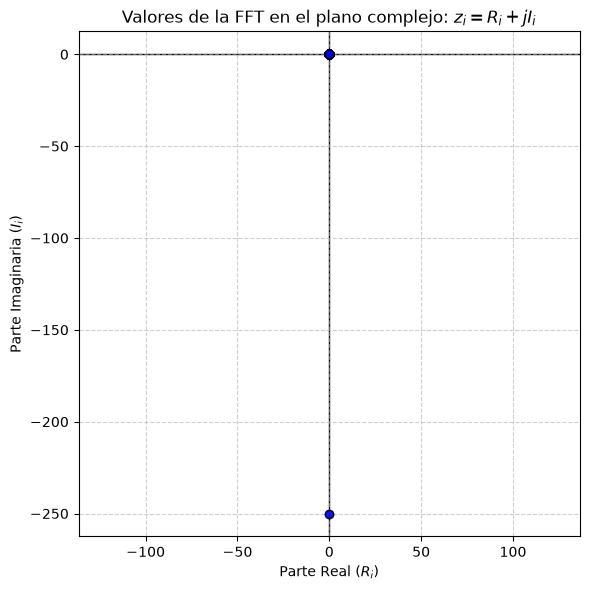

In [ ]:
# Se asume que la variable X_pos ya está calculada de los incisos anteriores
R_i = np.real(X_pos)
I_i = np.imag(X_pos)

plt.figure(figsize=(6, 6))
plt.scatter(R_i, I_i, color='blue', alpha=0.7, edgecolor='k', zorder=3)

# Ejes centrales que cruzan por el origen (0,0)
plt.axhline(0, color='black', linewidth=1, zorder=1)
plt.axvline(0, color='black', linewidth=1, zorder=1)

plt.title(r'Valores de la FFT en el plano complejo: $z_i = R_i + jI_i$')
plt.xlabel(r'Parte Real ($R_i$)')
plt.ylabel(r'Parte Imaginaria ($I_i$)')
plt.grid(True, linestyle='--', alpha=0.6, zorder=0)

# Obliga a que la escala de X e Y sea idéntica para no deformar el plano complejo
plt.axis('equal')
plt.tight_layout()
plt.show()

###  Para una señal con frecuencia de registro de $2^8$, graficar la relación: $\Delta t(t_f - t_i)$ vs. $\Delta f(f_f-f_i)$, donde $\Delta t$ es el vector de tiempo y $\Delta f$ es el vector de la frecuencia.

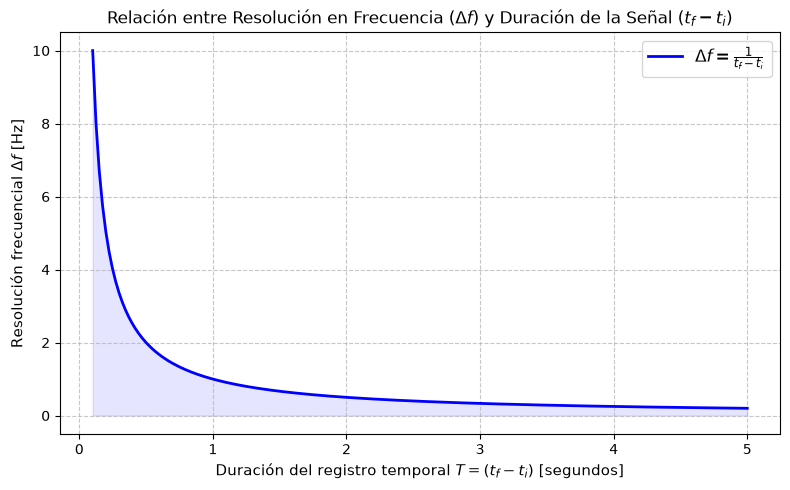

In [ ]:
# 1. Parámetro dado: Frecuencia de registro/muestreo
fs = 2**8  # 256 Hz
delta_t = 1 / fs  # Resolución temporal (constante)

# 2. Vector de duraciones de tiempo T = (t_f - t_i) en segundos
# Simulamos diferentes tamaños de ventana de tiempo desde 0.1s hasta 5s
T = np.linspace(0.1, 5.0, 200)

# 3. Relación teórica: La resolución en frecuencia es inversamente proporcional al tiempo total
# delta_f = 1 / T
delta_f = 1 / T

# 4. Visualización de la relación \Delta f vs \Delta t(t_f - t_i)
plt.figure(figsize=(8, 5))
plt.plot(T, delta_f, 'b-', linewidth=2, label=r'$\Delta f = \frac{1}{t_f - t_i}$')

# Decoración de la gráfica
plt.title(r'Relación entre Resolución en Frecuencia ($\Delta f$) y Duración de la Señal ($t_f - t_i$)', fontsize=12)
plt.xlabel(r'Duración del registro temporal $T = (t_f - t_i)$ [segundos]', fontsize=11)
plt.ylabel(r'Resolución frecuencial $\Delta f$ [Hz]', fontsize=11)

# Rellenar bajo la curva para mostrar la constancia del producto (Principio de Incertidumbre)
plt.fill_between(T, delta_f, color='blue', alpha=0.1)

plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

## EJEMPLO AUDIO - PELLEGRINI

In [ ]:
!pip install -q symbulate
# from symbulate import
from IPython.display import Audio

In [ ]:
from IPython.display import Audio

srate = 3000 #44100    # Frecuencia de muestreo (1024 Hz)
duracion = 2  # Duración del audio en segundos

frecuencia_do = 261.63   # Do (C4)
frecuencia_mi = 329.63   # Mi (E4)
frecuencia_sol = 392.00  # Sol (G4)
t = np.linspace(0, duracion, int(srate * duracion))

sig_do = np.sin(2 * np.pi * frecuencia_do * t)
sig_mi = np.sin(2 * np.pi * frecuencia_mi * t)
sig_sol = np.sin(2 * np.pi * frecuencia_sol * t)
acorde_do_mayor = sig_do + sig_mi + sig_sol
acorde_do_mayor /= np.max(np.abs(acorde_do_mayor))
Audio(acorde_do_mayor, rate=srate)

In [ ]:
sig_do = np.sin(2 * np.pi * frecuencia_do * t)
sig_mi = 20*np.sin(2 * np.pi * frecuencia_mi * t)
sig_sol = np.sin(2 * np.pi * frecuencia_sol * t)
acorde_do_mayor = sig_do + sig_mi + sig_sol
acorde_do_mayor /= np.max(np.abs(acorde_do_mayor))
Audio(acorde_do_mayor, rate=srate)

In [ ]:
sig_do = np.sin(2 * np.pi * frecuencia_do * t)
sig_mi = np.sin(2 * np.pi * frecuencia_mi * t)
sig_sol = 20*np.sin(2 * np.pi * frecuencia_sol * t)
acorde_do_mayor = sig_do + sig_mi + sig_sol
acorde_do_mayor /= np.max(np.abs(acorde_do_mayor))
Audio(acorde_do_mayor, rate=srate)

⭕ Sonido

* Graficar espectro de potencias

* Graficar $\phi_i(f_i)$ vs. $f_i$ Nota: $\phi_i = \arctan(\frac{I_i}{R_i})$ corresponde a las fases de Fourier

* Graficar valores de FFT: $z_i = R_i + jI_i$ en el plano complejo


In [ ]:
#inserte codigo

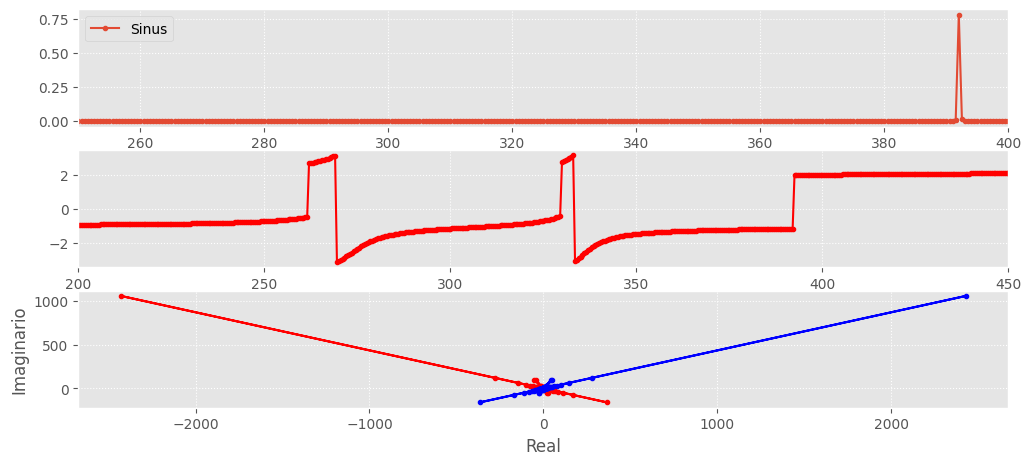

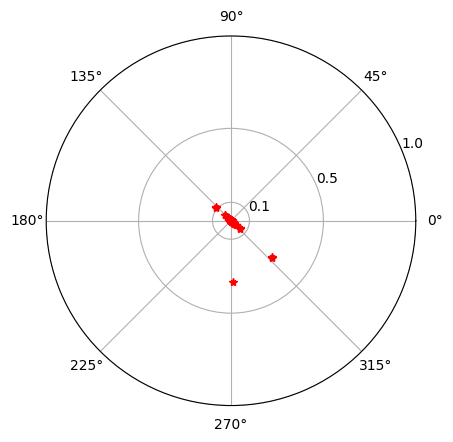

Tarea:
Investigar que es ruido blanco
